# GroundFormer recreate — visualization only

Notebook này dùng đúng output của notebook training `GroundFormer_NExT-GQA_WandB.ipynb`.

- Annotation: `/content/GroundFormer/datasets/nextgqa`
- Output recreate: Google Drive checkpoint folder chứa `test-res.json`, `test_ground_att.json`, `test_ground_ada.json`
- Không audit parameter, không so config với paper.
- Có một **video case study** tự chọn từ test set.

In [1]:
from pathlib import Path
import subprocess, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/GroundFormer")
if not ROOT.exists():
    print("Repo không còn trong runtime -> clone lại để lấy annotation...")
    subprocess.check_call([
        "git","clone","--depth","1",
        "https://github.com/jinhseo/GroundFormer.git",
        str(ROOT)
    ])

ANNO_DIR = ROOT / "datasets" / "nextgqa"
required_ann = [
    ANNO_DIR / "test.csv",
    ANNO_DIR / "gsub_test.json",
    ANNO_DIR / "frame2time_test.json",
]
missing = [p for p in required_ann if not p.exists()]
if missing:
    raise RuntimeError("Thiếu annotation:\n" + "\n".join(map(str, missing)))

print("✅ ANNO_DIR =", ANNO_DIR)
for p in required_ann:
    print("  ✅", p.name)

Mounted at /content/drive
Repo không còn trong runtime -> clone lại để lấy annotation...
✅ ANNO_DIR = /content/GroundFormer/datasets/nextgqa
  ✅ test.csv
  ✅ gsub_test.json
  ✅ frame2time_test.json


In [2]:
DEFAULT_SAVE_DIR = Path(
    "/content/drive/MyDrive/GroundFormer/checkpoints/"
    "nextgqa_bs16_official_15ep_fullwandb"
)
required_outputs = [
    "test-res.json",
    "test_ground_att.json",
    "test_ground_ada.json",
]

def valid_dir(p):
    p = Path(p)
    return p.is_dir() and all((p / x).exists() for x in required_outputs)

if valid_dir(DEFAULT_SAVE_DIR):
    SAVE_DIR = DEFAULT_SAVE_DIR
else:
    search_root = Path("/content/drive/MyDrive/GroundFormer")
    candidates = []
    if search_root.exists():
        for p in search_root.rglob("test-res.json"):
            if valid_dir(p.parent):
                candidates.append(p.parent)
    if not candidates:
        raise FileNotFoundError(
            "Không tìm thấy folder chứa đủ test-res.json, "
            "test_ground_att.json, test_ground_ada.json trên Drive."
        )
    candidates = sorted(
        set(candidates),
        key=lambda p: (p / "test-res.json").stat().st_mtime,
        reverse=True
    )
    SAVE_DIR = candidates[0]

print("✅ SAVE_DIR =", SAVE_DIR)
for x in required_outputs:
    print("  ✅", x)

✅ SAVE_DIR = /content/drive/MyDrive/GroundFormer/checkpoints/nextgqa_bs16_official_15ep_fullwandb
  ✅ test-res.json
  ✅ test_ground_att.json
  ✅ test_ground_ada.json


In [3]:
def load_json(p):
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)

qa = pd.read_csv(ANNO_DIR / "test.csv")
gt_ground = load_json(ANNO_DIR / "gsub_test.json")
frame2time = load_json(ANNO_DIR / "frame2time_test.json")

pred_qa = load_json(SAVE_DIR / "test-res.json")
pred_att = load_json(SAVE_DIR / "test_ground_att.json")
pred_ground = load_json(SAVE_DIR / "test_ground_ada.json")

print("QA rows:", len(qa))
print("GT videos:", len(gt_ground))
print("Pred QA:", len(pred_qa))
print("Pred attention:", len(pred_att))
print("Pred ground:", len(pred_ground))
display(qa.head(3))

QA rows: 5553
GT videos: 999
Pred QA: 5553
Pred attention: 5553
Pred ground: 5553


,video_id,frame_count,width,height,question,answer,qid,type,a0,a1,a2,a3,a4
0,2574374895,719,320,240,what did the baby do after throwing the green ...,lay on floor,8,TN,clap proudly,the lady sitting down,lay on floor,just picked it up,crawl
1,3083302557,1420,640,480,what did the lady do while turning back,thumbs up,3,TC,walk away,thumbs up,put down her club,applying cream on face,caressing for the dog
2,3621121750,1481,640,360,why did the boy punch his hand forwards in the...,listening to music and dancing,2,CW,to touch the sandals,to dance on the floor,to play,he is bored,listening to music and dancing


## Build sample-level table

In [4]:
def inter(a,b):
    return max(0.0, min(float(a[1]), float(b[1])) - max(float(a[0]), float(b[0])))

def tiou(a,b):
    I = inter(a,b)
    U = max(float(a[1]), float(b[1])) - min(float(a[0]), float(b[0]))
    return I/U if U > 0 else 0.0

def tiop(gt,pred):
    I = inter(gt,pred)
    L = float(pred[1]) - float(pred[0])
    if L <= 0:
        return float(float(gt[0]) <= float(pred[0]) <= float(gt[1]))
    return I/L

def best_gt(gt_spans, pred):
    vals = [(tiop(g,pred), tiou(g,pred), g) for g in gt_spans]
    if not vals:
        return 0.0, 0.0, [np.nan, np.nan]
    return max(x[0] for x in vals), max(x[1] for x in vals), max(vals, key=lambda x:(x[0],x[1]))[2]

def flatten(x):
    return np.asarray(x, dtype=float).reshape(-1)

def get_times(vid):
    x = frame2time[str(vid)]
    if isinstance(x, dict):
        try:
            keys = sorted(x.keys(), key=lambda k:int(k))
        except Exception:
            keys = list(x.keys())
        return np.array([float(x[k]) for k in keys])
    return flatten(x)

def att_info(kid, vid):
    a = flatten(pred_att[kid])
    t = get_times(vid)
    n = min(len(a), len(t))
    if n == 0:
        return np.nan, np.nan
    a, t = a[:n], t[:n]
    idx = int(np.nanargmax(a))
    z = np.nan_to_num(a, nan=0.0)
    z = z - z.min()
    if z.sum() <= 0:
        return float(t[idx]), np.nan
    p = z/z.sum()
    ent = -(p[p>0]*np.log(p[p>0])).sum()
    ent = ent / np.log(len(p)) if len(p)>1 else 0.0
    return float(t[idx]), float(ent)

In [5]:
TYPE_NAME = {
    "CW":"Causal-Why","CH":"Causal-How",
    "TN":"Temporal-Before&After","TC":"Temporal-When","TP":"Temporal-Present",
    "DC":"Descriptive-Count","DL":"Descriptive-Location","DO":"Descriptive-Other"
}

rows=[]
for _, r in qa.iterrows():
    vid, qid = str(r["video_id"]), str(r["qid"])
    kid = f"{vid}_{qid}"
    if vid not in gt_ground: continue
    if qid not in gt_ground[vid].get("location", {}): continue
    if kid not in pred_qa or kid not in pred_ground or kid not in pred_att: continue

    spans = gt_ground[vid]["location"][qid]
    pred = pred_ground[kid]
    iop, iou, gt = best_gt(spans, pred)

    y = pred_qa[kid]
    ans_id, pred_id = int(y["answer"]), int(y["prediction"])
    qa_ok = ans_id == pred_id
    gr_ok = iop >= 0.5
    peak_t, ent = att_info(kid, vid)

    rows.append({
        "kid":kid,"video_id":vid,"qid":qid,
        "type":str(r.get("type","")),
        "type_name":TYPE_NAME.get(str(r.get("type","")), str(r.get("type",""))),
        "question":r.get("question",""),
        "gt_answer":r.get(f"a{ans_id}",""),
        "pred_answer":r.get(f"a{pred_id}",""),
        "qa_correct":qa_ok,"ground_correct":gr_ok,"gqa_correct":qa_ok and gr_ok,
        "iop":iop,"iou":iou,
        "gt_start":float(gt[0]),"gt_end":float(gt[1]),
        "pred_start":float(pred[0]),"pred_end":float(pred[1]),
        "gt_len":max(0,float(gt[1])-float(gt[0])),
        "pred_len":max(0,float(pred[1])-float(pred[0])),
        "attention_peak_time":peak_t,
        "attention_entropy":ent,
        "num_gt_spans":len(spans)
    })

df = pd.DataFrame(rows)

def bucket(r):
    if r.qa_correct and r.ground_correct: return "QA đúng / Ground đúng"
    if r.qa_correct and not r.ground_correct: return "QA đúng / Ground sai"
    if not r.qa_correct and r.ground_correct: return "QA sai / Ground đúng"
    return "QA sai / Ground sai"

df["error_group"] = df.apply(bucket, axis=1)
print("Samples:", len(df))
display(df.head())

Samples: 5553


,kid,video_id,qid,type,type_name,question,gt_answer,pred_answer,qa_correct,ground_correct,...,gt_start,gt_end,pred_start,pred_end,gt_len,pred_len,attention_peak_time,attention_entropy,num_gt_spans,error_group
0,2574374895_8,2574374895,8,TN,Temporal-Before&After,what did the baby do after throwing the green ...,lay on floor,just picked it up,False,False,...,23.0,27.7,10.2,15.7,4.7,5.5,12.7,0.915222,1,QA sai / Ground sai
1,3083302557_3,3083302557,3,TC,Temporal-When,what did the lady do while turning back,thumbs up,thumbs up,True,False,...,10.8,12.3,16.2,21.7,1.5,5.5,18.7,0.944660,1,QA đúng / Ground sai
2,3621121750_2,3621121750,2,CW,Causal-Why,why did the boy punch his hand forwards in the...,listening to music and dancing,to play,False,False,...,15.9,20.2,36.2,42.2,4.3,6.0,39.2,0.943796,1,QA sai / Ground sai
3,4522565412_7,4522565412,7,CH,Causal-How,how did the man move the sides of the cube qui...,twist it,twist it,True,True,...,8.1,27.3,17.7,24.7,19.2,7.0,21.7,0.931751,1,QA đúng / Ground đúng
4,3747186945_6,3747186945,6,TN,Temporal-Before&After,how did the girl in braids feel after she fina...,happy and excited,happy and excited,True,False,...,39.1,42.9,35.7,46.2,3.8,10.5,41.7,0.863606,1,QA đúng / Ground sai


## 1. Tổng quan

,Metric,Value (%)
0,Acc@VQA,60.71
1,Acc@GQA,19.09
2,mIoP,31.00
3,mIoU,18.61


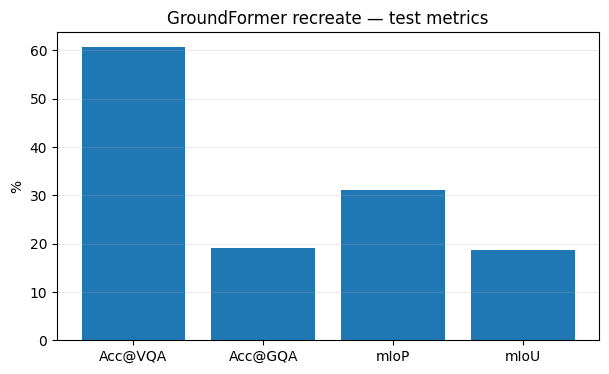

In [6]:
overall = pd.DataFrame({
    "Metric":["Acc@VQA","Acc@GQA","mIoP","mIoU"],
    "Value (%)":[
        100*df.qa_correct.mean(),
        100*df.gqa_correct.mean(),
        100*df.iop.mean(),
        100*df.iou.mean()
    ]
})
display(overall.round(2))

plt.figure(figsize=(7,4))
plt.bar(overall["Metric"], overall["Value (%)"])
plt.ylabel("%")
plt.title("GroundFormer recreate — test metrics")
plt.grid(axis="y", alpha=.25)
plt.show()

,error_group,n,mean_iop,mean_iou,share_%
2,QA đúng / Ground sai,2311,0.086,0.069,41.617
0,QA sai / Ground sai,1586,0.077,0.059,28.561
3,QA đúng / Ground đúng,1060,0.847,0.474,19.089
1,QA sai / Ground đúng,596,0.842,0.467,10.733


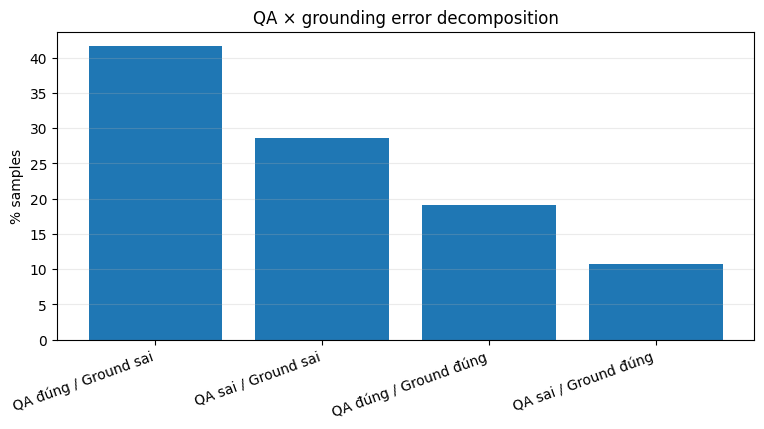

In [7]:
err = df.groupby("error_group").agg(
    n=("kid","size"), mean_iop=("iop","mean"), mean_iou=("iou","mean")
).reset_index()
err["share_%"] = 100*err.n/len(df)
display(err.sort_values("n", ascending=False).round(3))

plt.figure(figsize=(9,4))
tmp=err.sort_values("n", ascending=False)
plt.bar(tmp.error_group, tmp["share_%"])
plt.ylabel("% samples")
plt.title("QA × grounding error decomposition")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=.25)
plt.show()

## 2. IoP / IoU

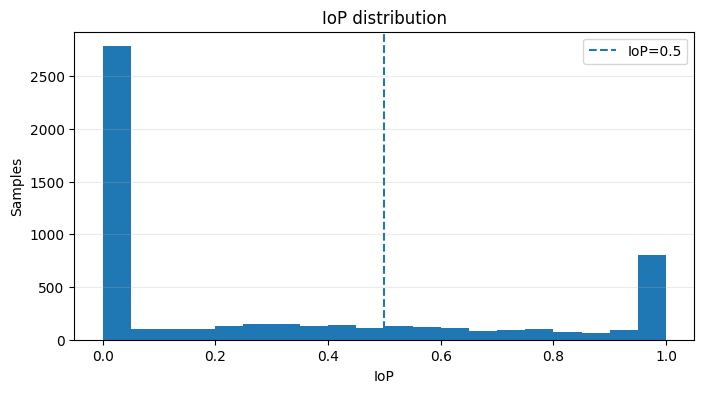

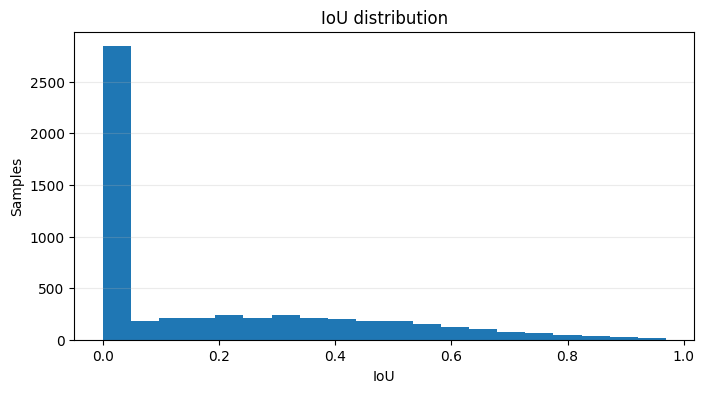

In [8]:
plt.figure(figsize=(8,4))
plt.hist(df.iop, bins=20)
plt.axvline(.5, linestyle="--", label="IoP=0.5")
plt.xlabel("IoP"); plt.ylabel("Samples"); plt.title("IoP distribution")
plt.legend(); plt.grid(axis="y", alpha=.25); plt.show()

plt.figure(figsize=(8,4))
plt.hist(df.iou, bins=20)
plt.xlabel("IoU"); plt.ylabel("Samples"); plt.title("IoU distribution")
plt.grid(axis="y", alpha=.25); plt.show()

## 3. Theo question type

,type_name,n,Acc_VQA,Acc_GQA,mIoP,mIoU
3,Temporal-Present,93,63.44,9.68,21.53,14.04
2,Temporal-Before&After,1356,58.78,14.90,24.96,17.28
1,Causal-Why,2456,60.67,20.03,32.75,18.67
0,Causal-How,796,61.93,21.11,34.44,19.88
4,Temporal-When,852,62.44,22.18,33.43,19.85


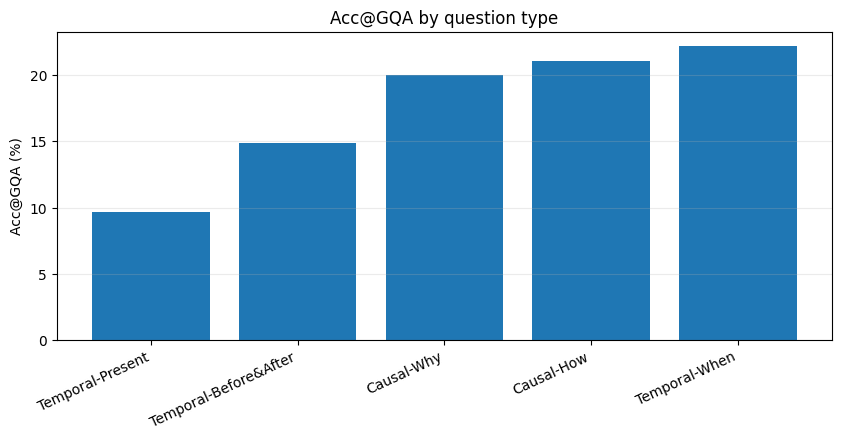

In [9]:
by_type = df.groupby("type_name").agg(
    n=("kid","size"),
    Acc_VQA=("qa_correct","mean"),
    Acc_GQA=("gqa_correct","mean"),
    mIoP=("iop","mean"),
    mIoU=("iou","mean")
).reset_index()

for c in ["Acc_VQA","Acc_GQA","mIoP","mIoU"]:
    by_type[c] *= 100

display(by_type.sort_values("Acc_GQA").round(2))

plt.figure(figsize=(10,4))
tmp=by_type.sort_values("Acc_GQA")
plt.bar(tmp.type_name, tmp.Acc_GQA)
plt.ylabel("Acc@GQA (%)")
plt.title("Acc@GQA by question type")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=.25)
plt.show()

## 4. Temporal span error

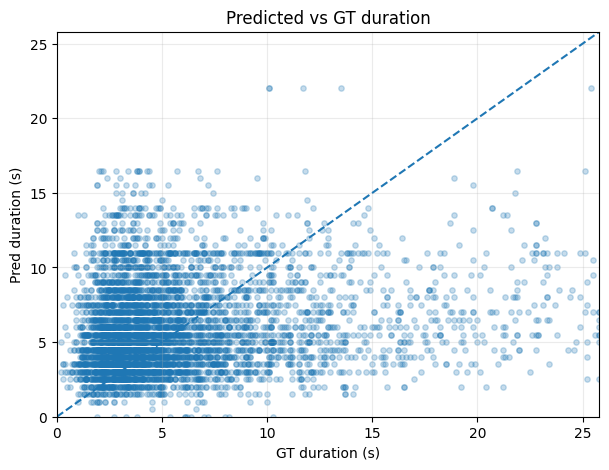

In [10]:
plt.figure(figsize=(7,5))
plt.scatter(df.gt_len, df.pred_len, alpha=.25, s=15)
vals=np.r_[df.gt_len.dropna(),df.pred_len.dropna()]
mx=np.percentile(vals,98) if len(vals) else 1
plt.plot([0,mx],[0,mx],linestyle="--")
plt.xlim(0,mx); plt.ylim(0,mx)
plt.xlabel("GT duration (s)")
plt.ylabel("Pred duration (s)")
plt.title("Predicted vs GT duration")
plt.grid(alpha=.25)
plt.show()

# 5. VIDEO EXAMPLE

Notebook tự chọn một video trong test set có từ 2 câu hỏi trở lên và có lỗi rõ.
Không cần raw `.mp4`: visualization dùng trực tiếp GT temporal evidence, predicted span và GroundFormer attention.

In [11]:
video_rows=[]
for vid, sub in df.groupby("video_id"):
    if len(sub)<2: continue
    pp=[]; gg=[]
    items=list(sub.itertuples(index=False))
    for i in range(len(items)):
        for j in range(i+1,len(items)):
            a,b=items[i],items[j]
            pp.append(tiou([a.pred_start,a.pred_end],[b.pred_start,b.pred_end]))
            gg.append(tiou([a.gt_start,a.gt_end],[b.gt_start,b.gt_end]))
    video_rows.append({
        "video_id":vid,
        "num_questions":len(sub),
        "num_errors":int((~sub.gqa_correct).sum()),
        "mean_iop":sub.iop.mean(),
        "pred_pair_iou":np.mean(pp) if pp else 0,
        "gt_pair_iou":np.mean(gg) if gg else 0
    })

video_df=pd.DataFrame(video_rows)
video_df["collapse_gap"]=video_df.pred_pair_iou-video_df.gt_pair_iou

eligible=video_df[(video_df.num_questions>=2)&(video_df.num_errors>=1)].copy()
eligible["score"]=eligible.collapse_gap.clip(lower=0)+(1-eligible.mean_iop)+eligible.num_errors/eligible.num_questions
case_video_id=str(eligible.sort_values("score",ascending=False).iloc[0].video_id)

print("✅ Example video:",case_video_id)
case_df=df[df.video_id==case_video_id].sort_values("qid").copy()
display(case_df[[
    "qid","type_name","question","gt_answer","pred_answer",
    "qa_correct","iop","iou",
    "gt_start","gt_end","pred_start","pred_end","attention_peak_time"
]].round(3))

✅ Example video: 3761582546


,qid,type_name,question,gt_answer,pred_answer,qa_correct,iop,iou,gt_start,gt_end,pred_start,pred_end,attention_peak_time
2773,5,Causal-Why,why is there a guy in black holding 2 sticks a...,show performance,show performance,True,0.0,0.0,0.1,7.3,71.2,85.2,79.7
1293,8,Temporal-Before&After,what does the lady in black do after walking n...,move wire,clap,False,0.0,0.0,50.2,57.1,71.2,85.2,79.7


### 5.1 GT vs prediction cho tất cả câu hỏi trong video

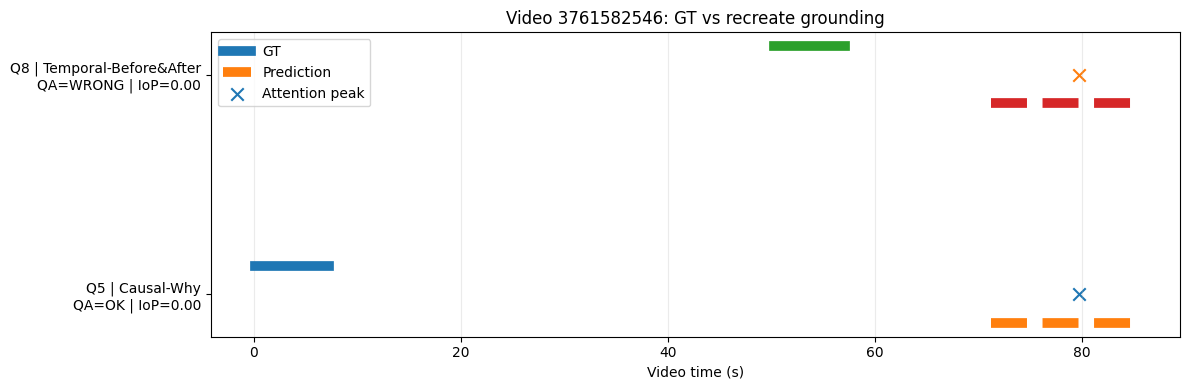

In [12]:
fig,ax=plt.subplots(figsize=(12,max(4,.9*len(case_df)+1)))
ys=[]; labels=[]
for y,r in enumerate(case_df.itertuples(index=False)):
    ax.plot([r.gt_start,r.gt_end],[y+.13,y+.13],linewidth=7,label="GT" if y==0 else None)
    ax.plot([r.pred_start,r.pred_end],[y-.13,y-.13],linewidth=7,linestyle="--",label="Prediction" if y==0 else None)
    if np.isfinite(r.attention_peak_time):
        ax.scatter(r.attention_peak_time,y,marker="x",s=80,label="Attention peak" if y==0 else None)
    ys.append(y)
    labels.append(f"Q{r.qid} | {r.type_name}\nQA={'OK' if r.qa_correct else 'WRONG'} | IoP={r.iop:.2f}")

ax.set_yticks(ys); ax.set_yticklabels(labels)
ax.set_xlabel("Video time (s)")
ax.set_title(f"Video {case_video_id}: GT vs recreate grounding")
ax.legend()
ax.grid(axis="x",alpha=.25)
plt.tight_layout()
plt.show()

### 5.2 Attention curve cho từng câu hỏi trong video

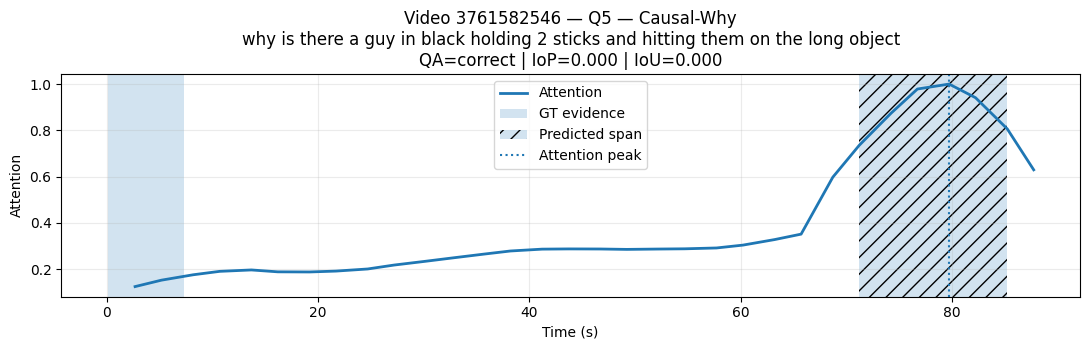

GT answer : show performance
Prediction: show performance
------------------------------------------------------------------------------------------


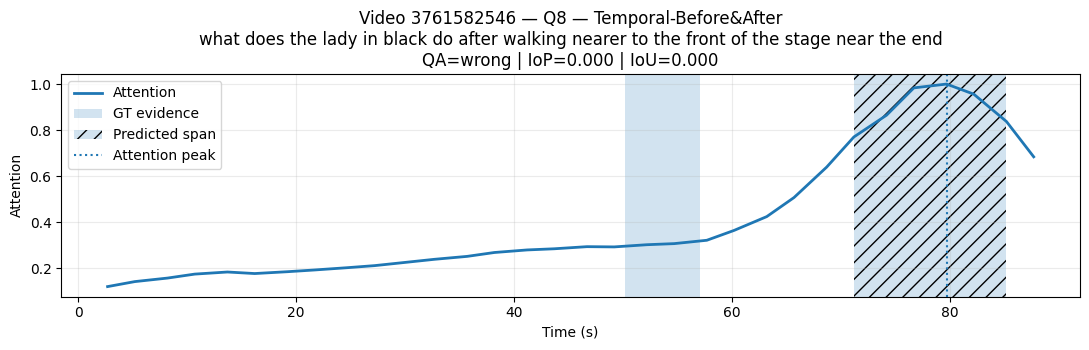

GT answer : move wire
Prediction: clap
------------------------------------------------------------------------------------------


In [13]:
for r in case_df.itertuples(index=False):
    att=flatten(pred_att[r.kid])
    times=get_times(case_video_id)
    n=min(len(att),len(times))
    att,times=att[:n],times[:n]

    plt.figure(figsize=(11,3.6))
    plt.plot(times,att,linewidth=2,label="Attention")

    spans=gt_ground[case_video_id]["location"][str(r.qid)]
    for j,sp in enumerate(spans):
        plt.axvspan(float(sp[0]),float(sp[1]),alpha=.2,label="GT evidence" if j==0 else None)

    plt.axvspan(r.pred_start,r.pred_end,alpha=.2,hatch="//",label="Predicted span")
    if np.isfinite(r.attention_peak_time):
        plt.axvline(r.attention_peak_time,linestyle=":",label="Attention peak")

    plt.title(
        f"Video {case_video_id} — Q{r.qid} — {r.type_name}\n"
        f"{r.question}\nQA={'correct' if r.qa_correct else 'wrong'} | IoP={r.iop:.3f} | IoU={r.iou:.3f}"
    )
    plt.xlabel("Time (s)")
    plt.ylabel("Attention")
    plt.legend()
    plt.grid(alpha=.25)
    plt.tight_layout()
    plt.show()

    print("GT answer :",r.gt_answer)
    print("Prediction:",r.pred_answer)
    print("-"*90)

### 5.3 Một lỗi đại diện trong video

,kid,question,gt_answer,pred_answer,qa_correct,iop,iou,gt_start,gt_end,pred_start,pred_end,attention_peak_time
2773,3761582546_5,why is there a guy in black holding 2 sticks a...,show performance,show performance,True,0.0,0.0,0.1,7.3,71.2,85.2,79.7


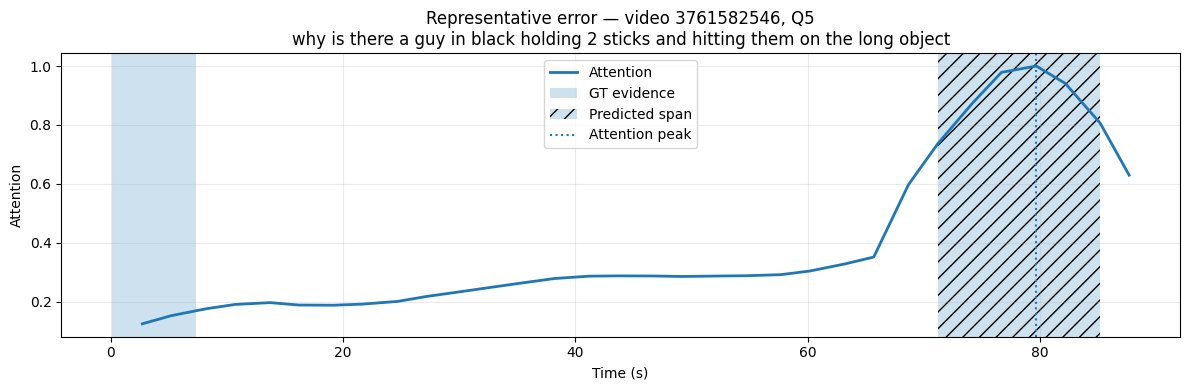

In [14]:
isolated=case_df[(case_df.qa_correct)&(~case_df.ground_correct)]
if len(isolated):
    focus=isolated.sort_values("iop").iloc[0]
else:
    failures=case_df[~case_df.gqa_correct]
    focus=failures.sort_values("iop").iloc[0] if len(failures) else case_df.sort_values("iop").iloc[0]

display(pd.DataFrame([focus[[
    "kid","question","gt_answer","pred_answer","qa_correct",
    "iop","iou","gt_start","gt_end","pred_start","pred_end","attention_peak_time"
]]]).round(3))

att=flatten(pred_att[focus.kid])
times=get_times(case_video_id)
n=min(len(att),len(times))
att,times=att[:n],times[:n]

plt.figure(figsize=(12,4))
plt.plot(times,att,linewidth=2,label="Attention")
for j,sp in enumerate(gt_ground[case_video_id]["location"][str(focus.qid)]):
    plt.axvspan(sp[0],sp[1],alpha=.22,label="GT evidence" if j==0 else None)
plt.axvspan(focus.pred_start,focus.pred_end,alpha=.22,hatch="//",label="Predicted span")
if np.isfinite(focus.attention_peak_time):
    plt.axvline(focus.attention_peak_time,linestyle=":",label="Attention peak")
plt.title(f"Representative error — video {case_video_id}, Q{focus.qid}\n{focus.question}")
plt.xlabel("Time (s)"); plt.ylabel("Attention")
plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

## 6. Export

In [15]:
EXPORT_DIR=SAVE_DIR/"visualization_analysis"
EXPORT_DIR.mkdir(parents=True,exist_ok=True)
df.to_csv(EXPORT_DIR/"test_sample_error_analysis.csv",index=False)
by_type.to_csv(EXPORT_DIR/"test_error_by_question_type.csv",index=False)
video_df.to_csv(EXPORT_DIR/"test_video_level_analysis.csv",index=False)
case_df.to_csv(EXPORT_DIR/f"example_video_{case_video_id}.csv",index=False)
print("✅ Saved:",EXPORT_DIR)

✅ Saved: /content/drive/MyDrive/GroundFormer/checkpoints/nextgqa_bs16_official_15ep_fullwandb/visualization_analysis
